In [1]:
## Running this from the "seacells_cu12" conda environment

## (For GPU usage): Additionally required explicitly specifying cuda version when installing cupy: pip install cupy-cuda12

In [2]:
import scanpy as sc
import anndata as ad
import muon as mu
from muon import MuData
import SEACells

import os
import sys
import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

sys.path.append('/nfs/casm/team215mg/users/od5/scripts/')
from single_cell_utils import *

import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import warnings

import session_info

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
findfont: Font family ['Raleway'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Lato'] not found. Falling back to DejaVu Sans.


In [3]:
session_info.show()

In [4]:
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/seacells_gex/tf_pilot/batch1/ipsc/'
os.makedirs(work_dir , exist_ok=True)

In [5]:
## Read raw adata object
mdata = mu.read_h5mu('/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/mdata/tf_pilot/batch1/ipsc/mdata_full.h5mu')
adata = mdata['rna']

In [6]:
adata

AnnData object with n_obs × n_vars = 6192 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5', 'anno_v1_nuc_gex', 'v3_leiden_1.5

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


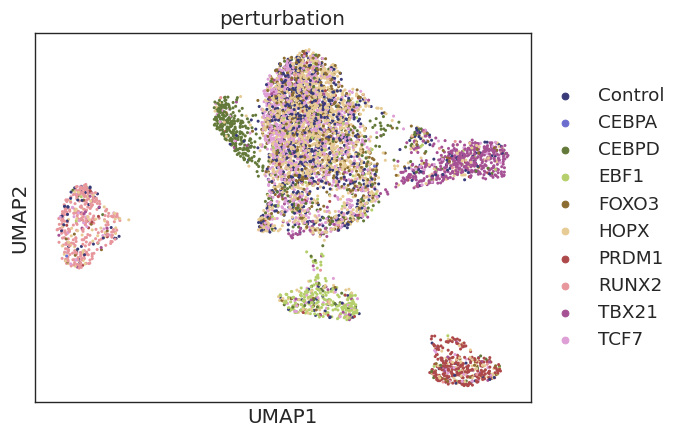

In [7]:
sc.pl.umap(adata, color='perturbation')

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, 'HOPX'),
  Text(1, 0, 'TCF7'),
  Text(2, 0, 'Control'),
  Text(3, 0, 'FOXO3'),
  Text(4, 0, 'TBX21'),
  Text(5, 0, 'CEBPD'),
  Text(6, 0, 'RUNX2'),
  Text(7, 0, 'PRDM1'),
  Text(8, 0, 'EBF1'),
  Text(9, 0, 'CEBPA')])

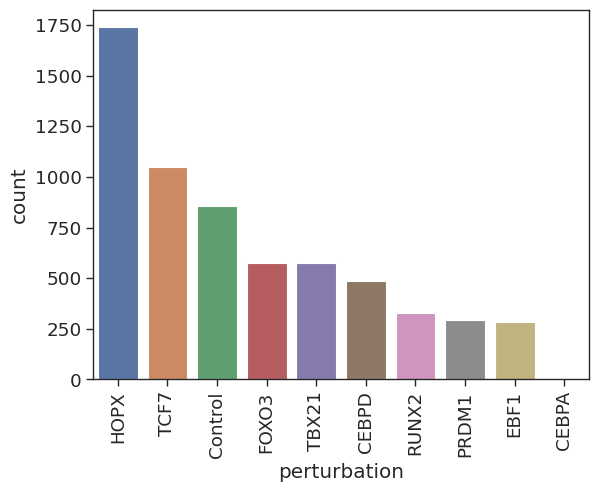

In [8]:
## We are going to be capping contributions per cell type and donor
## We are capping at level 2, to not prioritise "weird"/non-canonical states

cat_order = adata.obs['perturbation'].value_counts().index
sns.countplot(adata.obs, x= 'perturbation', order=cat_order)
plt.xticks(rotation=90)
# plt.axhline(y=10000, c='red', linestyle='--')

In [13]:
cell_counts = pd.crosstab(adata.obs['perturbation'], adata.obs['sample_ID'])
cell_counts['perturbation'] = cell_counts.index.tolist()
cell_counts = cell_counts.melt(id_vars = 'perturbation', value_name= 'count')

In [14]:
# ## Capping at 250 cells per donor
# maxN = 250
# mySeed=42
# cells2use =[]
# for i in range(cell_counts.shape[0]):
#     cells = adata.obs_names[(adata.obs['anno_v1_nuc_gex']==cell_counts['anno_v1_nuc_gex'][i]) & 
#     (adata.obs['souporcell_assignment']==cell_counts['souporcell_assignment'][i])]
#     if len(cells) > maxN:
#         np.random.seed(mySeed)
#         cells = np.random.choice(cells, maxN, replace=False)
#     cells2use += cells.tolist()

## Capping at 1000 cells per cell type
maxN = 1000
mySeed=42
cells2use =[]
for i in range(cell_counts.shape[0]):
    cells = adata.obs_names[(adata.obs['perturbation']==cell_counts['perturbation'][i])]
    if len(cells) > maxN:
        np.random.seed(mySeed)
        cells = np.random.choice(cells, maxN, replace=False)
    cells2use += cells.tolist()

In [15]:
len(cells2use)

5406

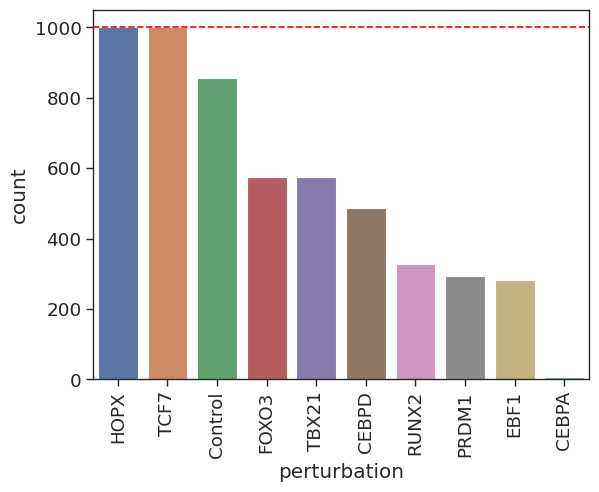

In [16]:
sns.countplot(adata.obs.loc[adata.obs_names.isin(cells2use),], x= 'perturbation', order=cat_order)
plt.xticks(rotation=90)
plt.axhline(y=1000, c='red', linestyle='--')

In [17]:
## Subset
adata = adata[adata.obs_names.isin(cells2use)].copy()

In [18]:
## Subset to perturbations with enough cells
adata = adata[~adata.obs['perturbation'].isin(['CEBPA'])]

In [19]:
## Subset mdata to common cells
common_cells = adata.obs_names

mdata = mdata[common_cells]

In [20]:
mdata

View of MuData object with n_obs × n_vars = 5400 × 118951
  2 modalities
    rna:	5400 x 36601
      obs:	'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5', 'anno_v1_nuc_gex', 'v3_leiden_1.5', 'v3_leiden_1', 'v3_leiden_0.9', 'v3_leiden_0.8'
      var:	'highly_variable', 'means', 'dispersions', 'dispersions_norm'
      uns:	'amulet_doublet_colors', 'anno_v1_nuc_gex_colors', 'hvg', 'leiden', 'log1p', 'neighbors', 'pca', 'perturbation_colors', 'rank_genes_groups', 'sample_ID_colors', 'sample_description_colors', 'umap', 'v1_leiden_100', 'v2_leiden_1.5', 'v2_leiden_1.5_colors', 'v3_leiden_0.8', 'v3_leiden_0.8_colors', 'v3_leiden_0.9', 'v3_leiden_0.9_colors', 'v3_leiden_1', 'v3_leiden_1.5', 'v3_leiden_1.5_colors', 'v3_leiden_1_colors'
      obsm:	'X_pca', 'X_umap'
      varm:	'PCs'
      layers:	'counts'
      obsp:	'connectivities', 'distances'
    atac:	5400 x 82350
      obs:	'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5', 'anno_v1_nuc_gex', 'v3_leiden_1.5', 'v3_leiden_1', 'v3_leiden_0.9', 'v3_leiden_0.8'

In [21]:
mdata.obsm = mdata['rna'].obsm.copy()
mdata.obs = mdata['rna'].obs.copy()

In [22]:
mdata.write_h5mu(work_dir + 'mdata.h5mu')

In [23]:
mdata = mu.read_h5mu(work_dir + 'mdata.h5mu')

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


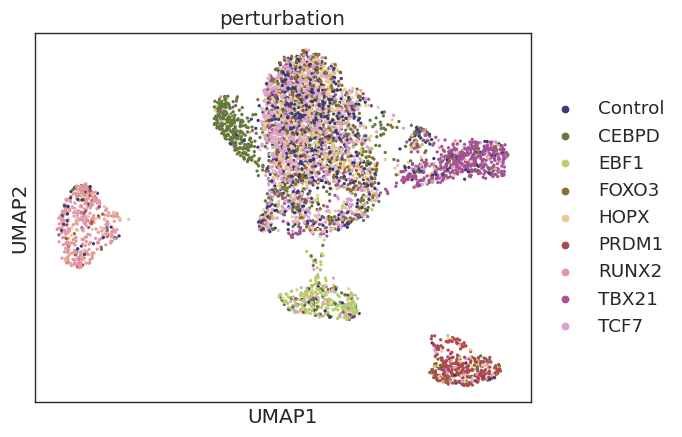

In [24]:
sc.pl.umap(mdata['rna'], color='perturbation')

### 1. Make seacells

Here we are using pseudocells for two reasons:
1. Reduce the sparsity of the data, which can improve our power to detect covariance between TFs, peaks and target genes.
2. Reduce computation time and resources needed

In [25]:
## User defined parameters

## Which embedding to use to build the kernel on
emb = 'X_umap'

## Additional parameters
n_waypoint_eigs = 10 # Number of eigenvalues to consider when initializing metacells

In [26]:
# ## We are doing this separately for each donor
# mdata.obs['SEACells_group'] = mdata.obs['donor'].astype(str)

# We are doing this separately for each organoid line
mdata.obs['SEACells_group'] = mdata.obs['perturbation'].astype(str)

In [27]:
mdata.obs['SEACells_group'].value_counts()

SEACells_group
TCF7       1000
HOPX       1000
Control     856
FOXO3       576
TBX21       576
CEBPD       486
RUNX2       329
PRDM1       295
EBF1        282
Name: count, dtype: int64

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


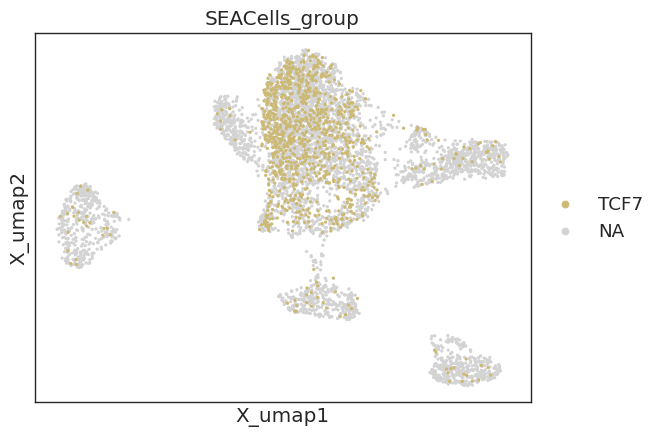

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


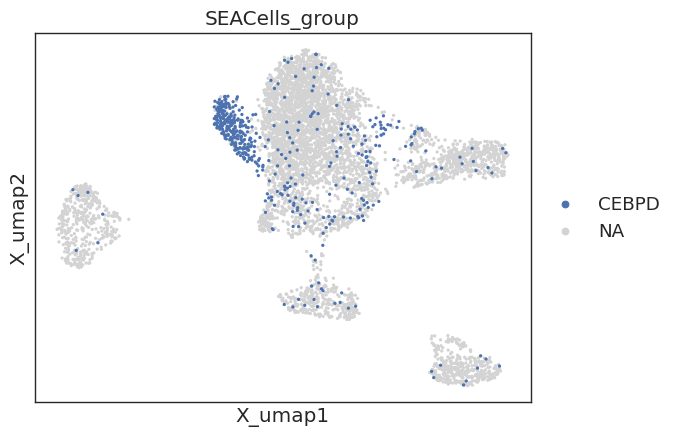

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


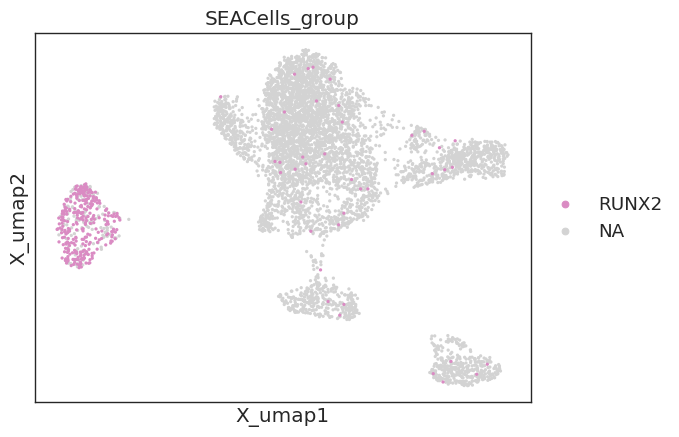

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


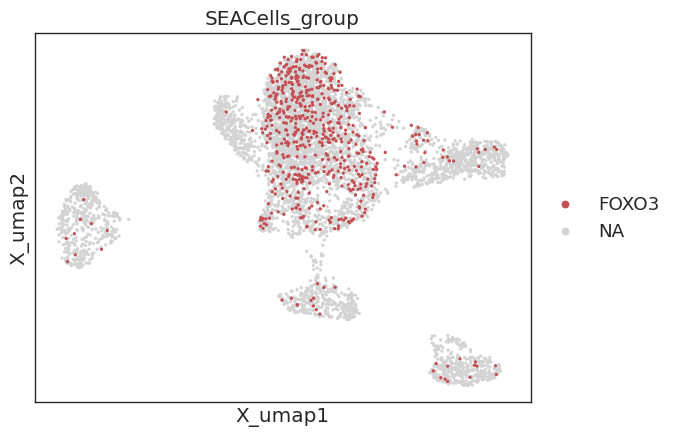

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


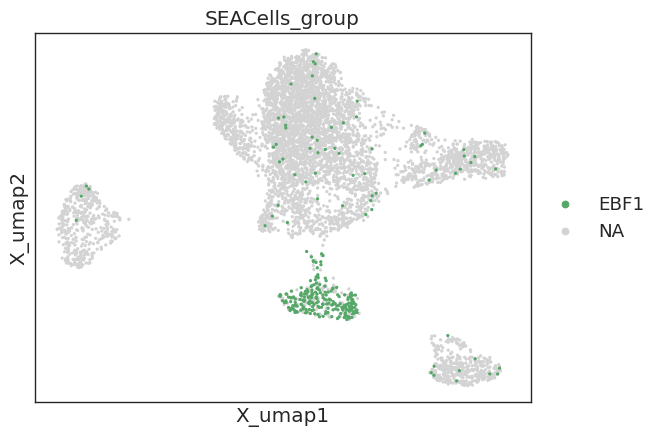

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


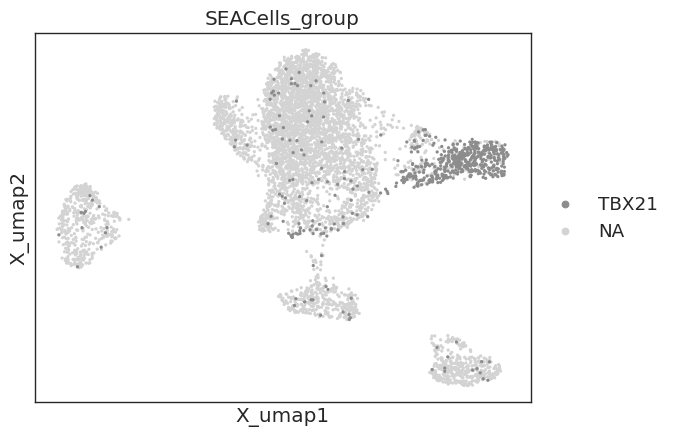

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


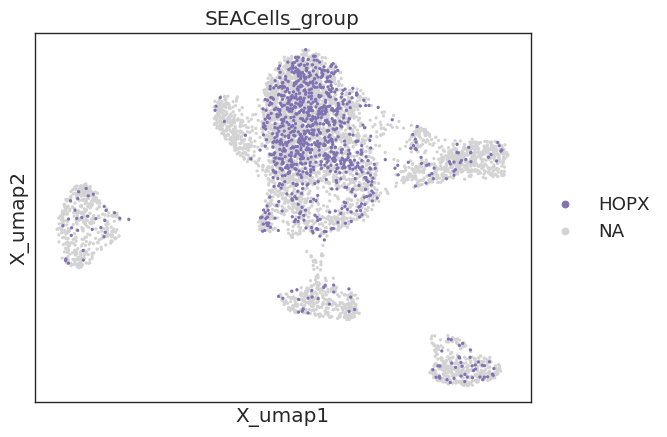

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


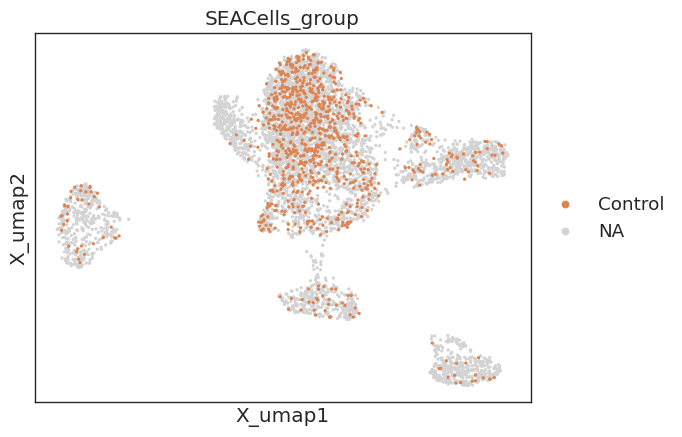

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


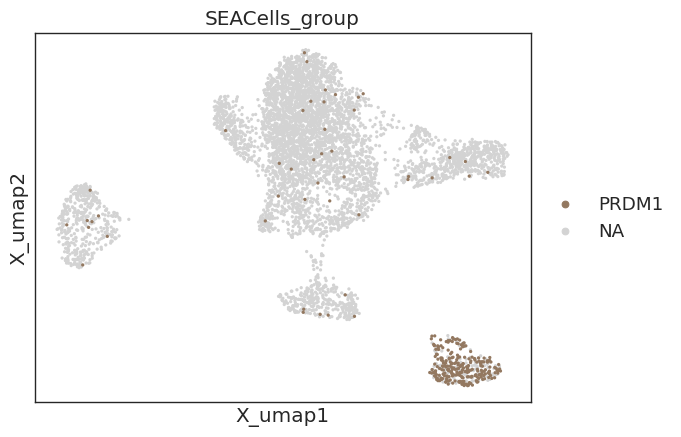

In [28]:
for g in mdata.obs['SEACells_group'].unique():
    sc.pl.embedding(mdata, color=['SEACells_group'], basis='X_umap', groups=g)

TCF7
Number of cells: 1000
Number of SEAcells: 50
Waypoints: 10
Welcome to SEACells!
Computing kNN graph using scanpy NN ...
Computing radius for adaptive bandwidth kernel...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 5447.57it/s]


Making graph symmetric...
Parameter graph_construction = union being used to build KNN graph...
Computing RBF kernel...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2143.42it/s]


Building similarity LIL matrix...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 3391.33it/s]


Constructing CSR matrix...
Building kernel on X_umap
Computing diffusion components from X_umap for waypoint initialization ... 
Determing nearest neighbor graph...
Done.
Sampling waypoints ...
Done.
Selecting 36 cells from waypoint initialization.
Initializing residual matrix using greedy column selection
Initializing f and g...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 1253.14it/s]


Selecting 14 cells from greedy initialization.


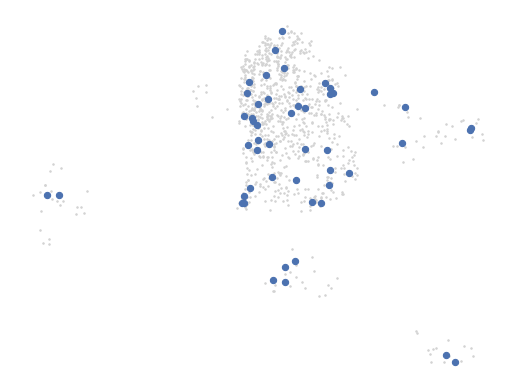

Randomly initialized A matrix.
Setting convergence threshold at 0.00054
Starting iteration 1.
Completed iteration 1.
Starting iteration 10.
Completed iteration 10.
Starting iteration 20.
Completed iteration 20.
Starting iteration 30.
Completed iteration 30.
Starting iteration 40.
Completed iteration 40.
Starting iteration 50.
Completed iteration 50.
Converged after 58 iterations.
CEBPD
Number of cells: 486
Number of SEAcells: 24
Waypoints: 10
Welcome to SEACells!
Computing kNN graph using scanpy NN ...
Computing radius for adaptive bandwidth kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 486/486 [00:00<00:00, 7497.74it/s]


Making graph symmetric...
Parameter graph_construction = union being used to build KNN graph...
Computing RBF kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 486/486 [00:00<00:00, 2759.05it/s]


Building similarity LIL matrix...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 486/486 [00:00<00:00, 3761.99it/s]


Constructing CSR matrix...
Building kernel on X_umap
Computing diffusion components from X_umap for waypoint initialization ... 
Determing nearest neighbor graph...
Done.
Sampling waypoints ...
Done.
Selecting 16 cells from waypoint initialization.
Initializing residual matrix using greedy column selection
Initializing f and g...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [00:00<00:00, 1855.70it/s]

Selecting 8 cells from greedy initialization.


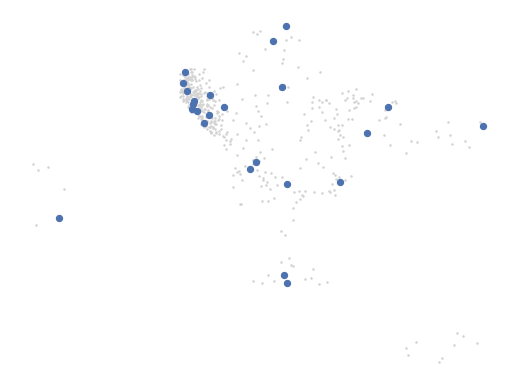

Randomly initialized A matrix.
Setting convergence threshold at 0.00037
Starting iteration 1.
Completed iteration 1.
Starting iteration 10.
Completed iteration 10.
Starting iteration 20.
Completed iteration 20.
Starting iteration 30.
Completed iteration 30.
Starting iteration 40.
Completed iteration 40.
Converged after 48 iterations.
RUNX2
Number of cells: 329
Number of SEAcells: 16
Waypoints: 10
Welcome to SEACells!
Computing kNN graph using scanpy NN ...
Computing radius for adaptive bandwidth kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 329/329 [00:00<00:00, 7485.20it/s]


Making graph symmetric...
Parameter graph_construction = union being used to build KNN graph...
Computing RBF kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 329/329 [00:00<00:00, 2804.45it/s]


Building similarity LIL matrix...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 329/329 [00:00<00:00, 3825.45it/s]


Constructing CSR matrix...
Building kernel on X_umap
Computing diffusion components from X_umap for waypoint initialization ... 
Determing nearest neighbor graph...
Done.
Sampling waypoints ...
Done.
Selecting 9 cells from waypoint initialization.
Initializing residual matrix using greedy column selection
Initializing f and g...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:00<00:00, 2247.68it/s]


Selecting 7 cells from greedy initialization.


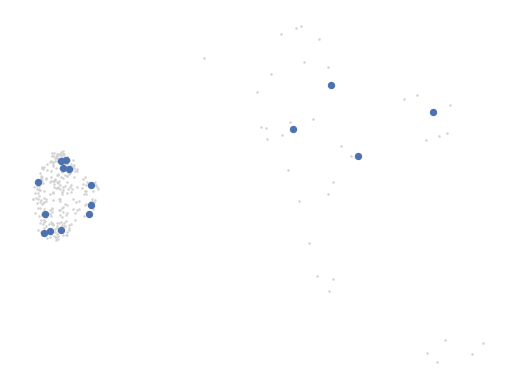

Randomly initialized A matrix.
Setting convergence threshold at 0.00031
Starting iteration 1.
Completed iteration 1.
Starting iteration 10.
Completed iteration 10.
Converged after 19 iterations.
FOXO3
Number of cells: 576
Number of SEAcells: 28
Waypoints: 10
Welcome to SEACells!
Computing kNN graph using scanpy NN ...
Computing radius for adaptive bandwidth kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 576/576 [00:00<00:00, 6567.94it/s]


Making graph symmetric...
Parameter graph_construction = union being used to build KNN graph...
Computing RBF kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 576/576 [00:00<00:00, 2445.86it/s]


Building similarity LIL matrix...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 576/576 [00:00<00:00, 3713.70it/s]


Constructing CSR matrix...
Building kernel on X_umap
Computing diffusion components from X_umap for waypoint initialization ... 
Determing nearest neighbor graph...
Done.
Sampling waypoints ...
Done.
Selecting 23 cells from waypoint initialization.
Initializing residual matrix using greedy column selection
Initializing f and g...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15/15 [00:00<00:00, 1954.11it/s]

Selecting 5 cells from greedy initialization.


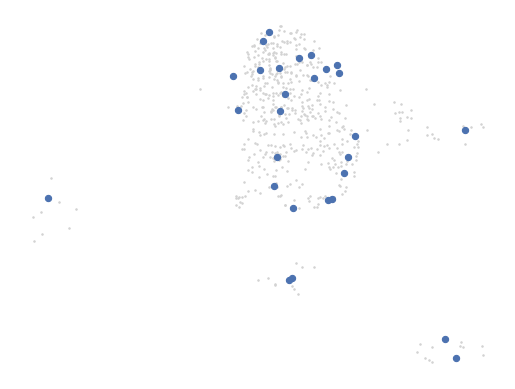

Randomly initialized A matrix.
Setting convergence threshold at 0.00041
Starting iteration 1.
Completed iteration 1.
Starting iteration 10.
Completed iteration 10.
Starting iteration 20.
Completed iteration 20.
Starting iteration 30.
Completed iteration 30.
Starting iteration 40.
Completed iteration 40.
Converged after 41 iterations.
EBF1
Number of cells: 282
Number of SEAcells: 14
Waypoints: 10
Welcome to SEACells!
Computing kNN graph using scanpy NN ...
Computing radius for adaptive bandwidth kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 282/282 [00:00<00:00, 6798.25it/s]


Making graph symmetric...
Parameter graph_construction = union being used to build KNN graph...
Computing RBF kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 282/282 [00:00<00:00, 2460.49it/s]


Building similarity LIL matrix...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 282/282 [00:00<00:00, 3909.75it/s]


Constructing CSR matrix...
Building kernel on X_umap
Computing diffusion components from X_umap for waypoint initialization ... 
Determing nearest neighbor graph...
Done.
Sampling waypoints ...
Done.
Selecting 9 cells from waypoint initialization.
Initializing residual matrix using greedy column selection
Initializing f and g...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15/15 [00:00<00:00, 2317.04it/s]

Selecting 5 cells from greedy initialization.


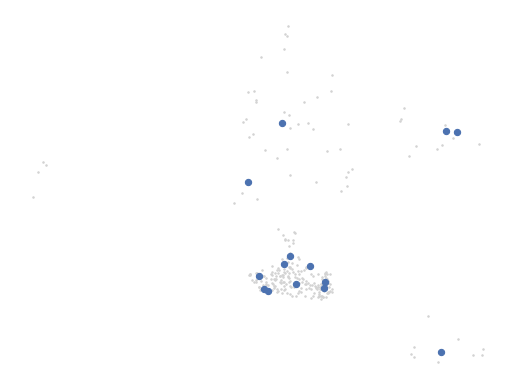

Randomly initialized A matrix.
Setting convergence threshold at 0.00028
Starting iteration 1.
Completed iteration 1.
Starting iteration 10.
Completed iteration 10.
Starting iteration 20.
Completed iteration 20.
Converged after 28 iterations.
TBX21
Number of cells: 576
Number of SEAcells: 28
Waypoints: 10
Welcome to SEACells!
Computing kNN graph using scanpy NN ...
Computing radius for adaptive bandwidth kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 576/576 [00:00<00:00, 6549.18it/s]


Making graph symmetric...
Parameter graph_construction = union being used to build KNN graph...
Computing RBF kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 576/576 [00:00<00:00, 2417.73it/s]


Building similarity LIL matrix...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 576/576 [00:00<00:00, 3717.52it/s]


Constructing CSR matrix...
Building kernel on X_umap
Computing diffusion components from X_umap for waypoint initialization ... 
Determing nearest neighbor graph...
Done.
Sampling waypoints ...
Done.
Selecting 22 cells from waypoint initialization.
Initializing residual matrix using greedy column selection
Initializing f and g...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [00:00<00:00, 1742.50it/s]


Selecting 6 cells from greedy initialization.


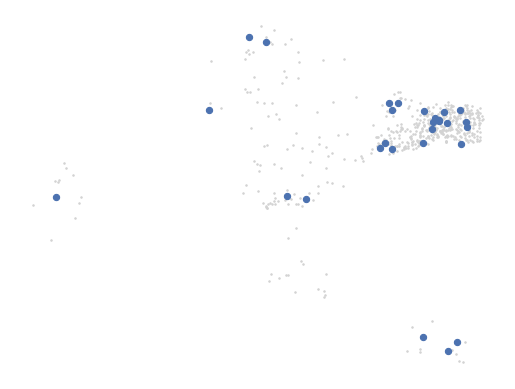

Randomly initialized A matrix.
Setting convergence threshold at 0.00041
Starting iteration 1.
Completed iteration 1.
Starting iteration 10.
Completed iteration 10.
Starting iteration 20.
Completed iteration 20.
Starting iteration 30.
Completed iteration 30.
Starting iteration 40.
Completed iteration 40.
Converged after 42 iterations.
HOPX
Number of cells: 1000
Number of SEAcells: 50
Waypoints: 10
Welcome to SEACells!
Computing kNN graph using scanpy NN ...
Computing radius for adaptive bandwidth kernel...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 5869.30it/s]


Making graph symmetric...
Parameter graph_construction = union being used to build KNN graph...
Computing RBF kernel...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2237.23it/s]


Building similarity LIL matrix...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 3534.16it/s]


Constructing CSR matrix...
Building kernel on X_umap
Computing diffusion components from X_umap for waypoint initialization ... 
Determing nearest neighbor graph...
Done.
Sampling waypoints ...
Done.
Selecting 38 cells from waypoint initialization.
Initializing residual matrix using greedy column selection
Initializing f and g...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 22/22 [00:00<00:00, 1314.79it/s]


Selecting 12 cells from greedy initialization.


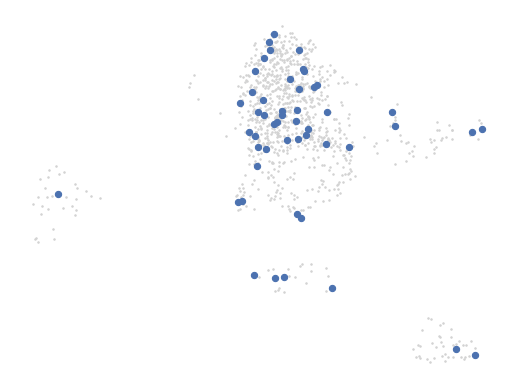

Randomly initialized A matrix.
Setting convergence threshold at 0.00054
Starting iteration 1.
Completed iteration 1.
Starting iteration 10.
Completed iteration 10.
Starting iteration 20.
Completed iteration 20.
Starting iteration 30.
Completed iteration 30.
Converged after 31 iterations.
Control
Number of cells: 856
Number of SEAcells: 42
Waypoints: 10
Welcome to SEACells!
Computing kNN graph using scanpy NN ...
Computing radius for adaptive bandwidth kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 856/856 [00:00<00:00, 6058.19it/s]


Making graph symmetric...
Parameter graph_construction = union being used to build KNN graph...
Computing RBF kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 856/856 [00:00<00:00, 2340.81it/s]


Building similarity LIL matrix...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 856/856 [00:00<00:00, 3593.66it/s]


Constructing CSR matrix...
Building kernel on X_umap
Computing diffusion components from X_umap for waypoint initialization ... 
Determing nearest neighbor graph...
Done.
Sampling waypoints ...
Done.
Selecting 32 cells from waypoint initialization.
Initializing residual matrix using greedy column selection
Initializing f and g...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 1506.57it/s]

Selecting 10 cells from greedy initialization.


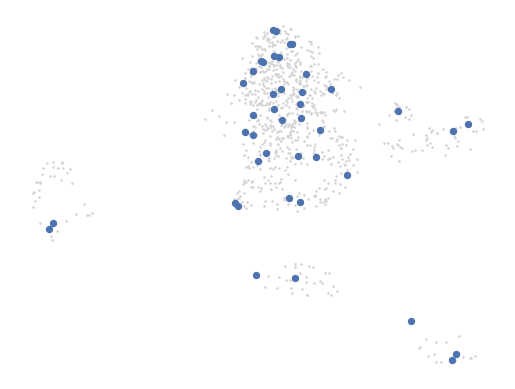

Randomly initialized A matrix.
Setting convergence threshold at 0.00050
Starting iteration 1.
Completed iteration 1.
Starting iteration 10.
Completed iteration 10.
Starting iteration 20.
Completed iteration 20.
Starting iteration 30.
Completed iteration 30.
Converged after 32 iterations.
PRDM1
Number of cells: 295
Number of SEAcells: 14
Waypoints: 10
Welcome to SEACells!
Computing kNN graph using scanpy NN ...
Computing radius for adaptive bandwidth kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 295/295 [00:00<00:00, 6841.46it/s]


Making graph symmetric...
Parameter graph_construction = union being used to build KNN graph...
Computing RBF kernel...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 295/295 [00:00<00:00, 2542.57it/s]


Building similarity LIL matrix...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 295/295 [00:00<00:00, 3900.83it/s]


Constructing CSR matrix...
Building kernel on X_umap
Computing diffusion components from X_umap for waypoint initialization ... 
Determing nearest neighbor graph...
Done.
Sampling waypoints ...
Done.
Selecting 9 cells from waypoint initialization.
Initializing residual matrix using greedy column selection
Initializing f and g...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15/15 [00:00<00:00, 2373.96it/s]


Selecting 5 cells from greedy initialization.


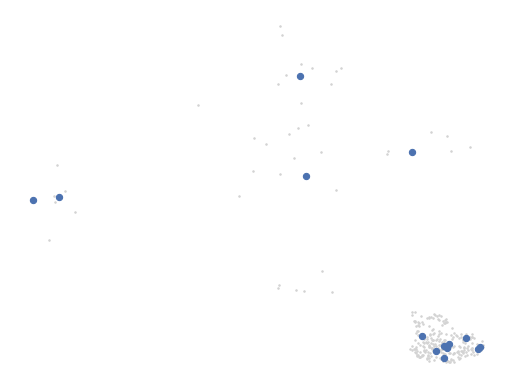

Randomly initialized A matrix.
Setting convergence threshold at 0.00030
Starting iteration 1.
Completed iteration 1.
Starting iteration 10.
Completed iteration 10.
Starting iteration 20.
Completed iteration 20.
Starting iteration 30.
Completed iteration 30.
Starting iteration 40.
Completed iteration 40.
Starting iteration 50.
Completed iteration 50.
Starting iteration 60.
Completed iteration 60.
Starting iteration 70.
Completed iteration 70.
Starting iteration 80.
Completed iteration 80.
Starting iteration 90.
Completed iteration 90.
Starting iteration 100.
Completed iteration 100.
Ignoring runtime warning: Warning: Algorithm has not converged - you may need to increase the maximum number of iterations


In [29]:
mdatas_obs_dict = {}
for g in mdata.obs['SEACells_group'].unique():
    print(g)
    mdata_sub = mdata[mdata.obs['SEACells_group']==g].copy()
    print(("Number of cells: " + str(mdata_sub.obs.shape[0])))

    ## Number of metacells - we aim for 20 cells per metacell
    n_SEACells = mdata_sub.shape[0]//20
    print("Number of SEAcells: " + str(n_SEACells))
    print('Waypoints: ' + str(min(n_waypoint_eigs, n_SEACells)))

    model = SEACells.core.SEACells(mdata_sub, 
                      build_kernel_on=emb, 
                      n_SEACells=n_SEACells, 
                      n_waypoint_eigs=min(n_waypoint_eigs, n_SEACells),
                      convergence_epsilon = 1e-5,
                                   use_gpu=False)
    
    ## Initialise model
    model.construct_kernel_matrix()
    M = model.kernel_matrix
    
    # Initialise archetypes
    model.initialize_archetypes()
    
    # Plot the initilization to ensure they are spread across phenotypic space
    SEACells.plot.plot_initialization(mdata_sub, model, plot_basis='X_umap')

    ## Suppressing warnings about convergence
    warnings.filterwarnings("ignore", category=RuntimeWarning)
    # Fit the model
    try:
        model.fit(min_iter=10, max_iter=100)
    except RuntimeWarning as rw:
        print(f"Ignoring runtime warning: {rw}")

    mdata_sub.obs['SEACell'] = g + '-' + mdata_sub.obs['SEACell']
    
    mdatas_obs_dict[g] = mdata_sub.obs.copy()

In [30]:
seacells_obs = pd.concat([i for i in mdatas_obs_dict.values()])

In [31]:
seacells_obs 

,rna:sample_barcode,rna:barcode,rna:gex_barcode,rna:atac_barcode,rna:cellranger_gex_umis_count,rna:cellranger_gex_genes_count,rna:snap_atac_fragments,rna:snap_TSS_enrichment,rna:f_intronic,rna:cellranger_is_cell,...,is_valid_doublet,v1_leiden_100,v2_leiden_1.5,anno_v1_nuc_gex,v3_leiden_1.5,v3_leiden_1,v3_leiden_0.9,v3_leiden_0.8,SEACells_group,SEACell
index,,,,,,,,,,,,,,,,,,,,,
multi_Imm_NK15385635-AAACAGCCAGCACGAA-1,multi_Imm_NK15385635-AAACAGCCAGCACGAA-1,AAACAGCCAGCACGAA-1,AAACAGCCAGCACGAA-1,ACAGCGGGTAATCACC-1,8717,3867,1622.0,17.786561,0.286796,1,...,0,253,0,Unperturbed,8,4,4,3,TCF7,TCF7-SEACell-30
multi_Imm_NK15385635-AAACAGCCATTCAGCA-1,multi_Imm_NK15385635-AAACAGCCATTCAGCA-1,AAACAGCCATTCAGCA-1,AAACAGCCATTCAGCA-1,ACAGCGGGTAAGGGCT-1,14635,5390,23745.0,12.515398,0.438606,1,...,0,252,15,Unperturbed,7,1,1,0,TCF7,TCF7-SEACell-12
multi_Imm_NK15385635-AAACCGAAGAAAGCAT-1,multi_Imm_NK15385635-AAACCGAAGAAAGCAT-1,AAACCGAAGAAAGCAT-1,AAACCGAAGAAAGCAT-1,TGACTATTCGACAAAC-1,9592,4255,14447.0,11.179361,0.275229,1,...,0,109,9,Unperturbed,15,5,5,5,TCF7,TCF7-SEACell-17
multi_Imm_NK15385635-AAACCGAAGGCTAAGA-1,multi_Imm_NK15385635-AAACCGAAGGCTAAGA-1,AAACCGAAGGCTAAGA-1,AAACCGAAGGCTAAGA-1,TGACTATTCATTAGTC-1,7963,3538,19406.0,11.748252,0.203943,1,...,0,457,8,Unperturbed,9,5,5,5,TCF7,TCF7-SEACell-9
multi_Imm_NK15385635-AAACCGAAGGGATTAG-1,multi_Imm_NK15385635-AAACCGAAGGGATTAG-1,AAACCGAAGGGATTAG-1,AAACCGAAGGGATTAG-1,TGACTATTCAGTACCC-1,8249,3935,4212.0,12.242424,0.381986,1,...,0,851,0,Unperturbed,1,2,2,1,TCF7,TCF7-SEACell-25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
multi_Imm_NK15385635-TTGTCCCAGTAACGAG-1,multi_Imm_NK15385635-TTGTCCCAGTAACGAG-1,TTGTCCCAGTAACGAG-1,TTGTCCCAGTAACGAG-1,TTAGCGCTCTATCGGC-1,19142,6081,33922.0,11.658213,0.373733,1,...,0,367,5,PRDM1,5,7,7,7,PRDM1,PRDM1-SEACell-7
multi_Imm_NK15385635-TTGTGAGGTGAGCACT-1,multi_Imm_NK15385635-TTGTGAGGTGAGCACT-1,TTGTGAGGTGAGCACT-1,TTGTGAGGTGAGCACT-1,GTTTGCTCAATAGAAG-1,6423,3353,5395.0,7.224026,0.456017,1,...,0,61,5,PRDM1,5,7,7,7,PRDM1,PRDM1-SEACell-12
multi_Imm_NK15385635-TTGTGCGAGTAGCGCC-1,multi_Imm_NK15385635-TTGTGCGAGTAGCGCC-1,TTGTGCGAGTAGCGCC-1,TTGTGCGAGTAGCGCC-1,TACTTCCTCTGTCAGC-1,9680,4243,21067.0,17.447770,0.471901,1,...,0,238,5,PRDM1,5,7,7,7,PRDM1,PRDM1-SEACell-7


In [32]:
mdata.obs = pd.merge(mdata.obs, seacells_obs['SEACell'], left_index=True, right_index=True, how='left')

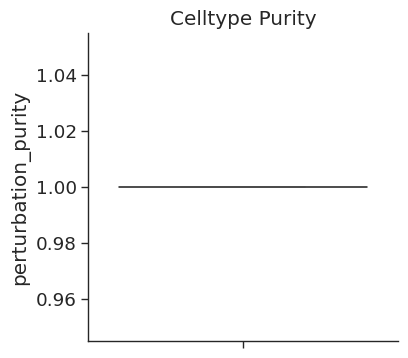

In [33]:
SEACell_purity = SEACells.evaluate.compute_celltype_purity(mdata, 'perturbation')

plt.figure(figsize=(4,4))
sns.boxplot(data=SEACell_purity, y='perturbation_purity')
plt.title('Celltype Purity')
sns.despine()
plt.show()
plt.close()

Determing nearest neighbor graph...


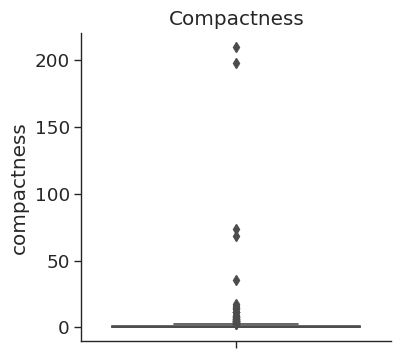

,compactness
SEACell,
CEBPD-SEACell-0,0.005970
CEBPD-SEACell-1,0.750246
CEBPD-SEACell-10,0.040708
CEBPD-SEACell-11,5.668808
CEBPD-SEACell-12,0.047000


In [34]:
compactness = SEACells.evaluate.compactness(mdata, emb)

plt.figure(figsize=(4,4))
sns.boxplot(data=compactness, y='compactness')
plt.title('Compactness')
sns.despine()
plt.show()
plt.close()

compactness.head()

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/SEACells-0.3.3-py3.8.egg/SEACells/plot.py:130: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(label_df.groupby("SEACell").count().iloc[:, 0], bins=bins)


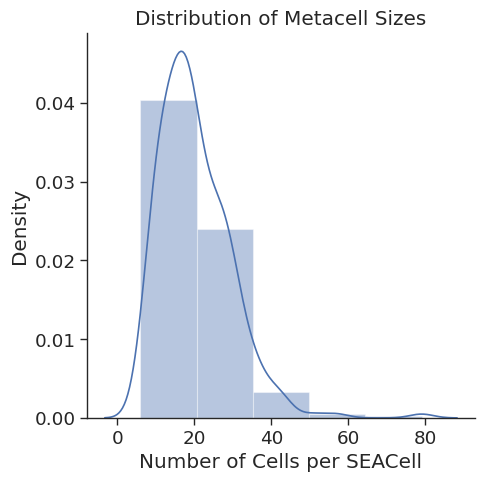

In [35]:
seacell_sizes = SEACells.plot.plot_SEACell_sizes(mdata, bins=5)

In [36]:
mdata.obs['SEACell'].value_counts().describe()

count    266.000000
mean      20.300752
std        9.402918
min        6.000000
25%       14.000000
50%       19.000000
75%       26.000000
max       79.000000
Name: count, dtype: float64

In [37]:
## Aggregating profiles by SEACell
mdata['rna'].obs['SEACell'] = mdata.obs['SEACell'].copy()
mdata['atac'].obs['SEACell'] = mdata.obs['SEACell'].copy()

In [38]:
## Export full object
mdata.write((work_dir + "mdata.h5mu"))

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/anndata/_core/anndata.py:1230: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[key] = c


In [39]:
mdata

MuData object with n_obs × n_vars = 5400 × 118951
  obs:	'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5', 'anno_v1_nuc_gex', 'v3_leiden_1.5', 'v3_leiden_1', 'v3_leiden_0.9', 'v3_leiden_0.8', 'SEACells_group', 'SEACell'
  uns:	'SEACells_group_colors'
  obsm:	'X_pca', 'X_umap'
  2 modalities
    rna:	5400 x 36601
      obs:	'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5', 'anno_v1_nuc_gex', 'v3_leiden_1.5', 'v3_leiden_1', 'v3_leiden_0.9', 'v3_leiden_0.8', 'SEACell'
      var:	'highly_variable', 'means', 'dispersions', 'dispersions_norm'
      uns:	'amulet_doublet_colors', 'anno_v1_nuc_gex_colors', 'hvg', 'leiden', 'log1p', 'neighbors', 'pca', 'perturbation_colors', 'rank_genes_groups', 'sample_ID_colors', 'sample_description_colors', 'umap', 'v1_leiden_100', 'v2_leiden_1.5', 'v2_leiden_1.5_colors', 'v3_leiden_0.8', 'v3_leiden_0.8_colors', 'v3_leiden_0.9', 'v3_leiden_0.9_colors', 'v3_leiden_1', 'v3_leiden_1.5', 'v3_leiden_1.5_colors', 'v3_leiden_1_colors'
      obsm:	'X_pca', 'X_umap'
      varm:	'PCs'
      layers:	'counts'
      obsp:	'connectivities', 'distances'
    atac:	5400 x 82350
      obs:	'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5', 'anno_v1_nuc_gex', 'v3_leiden_1.5', 'v3_leiden_1', 'v3_leiden_0.9', 'v3_leiden_0.8', 'SEACell'

In [40]:
## Also export metadata
mdata.obs.to_csv((work_dir + "cell_anno_with_seacells.csv"))

In [41]:
## Converting to CSR matrix should speed up aggregation a lot
mdata['atac'].X = mdata['atac'].X.tocsr()

In [42]:
## Make sure that we still have counts in rna.X
mdata['rna'].X.max()

6.1103971234966465

In [43]:
## Since we only use a small number of neighbors per metacell, we can use the hard assignment here.
SEACell_rna = SEACells.core.summarize_by_SEACell(mdata['rna'], celltype_label='perturbation', SEACells_label='SEACell', summarize_layer='X')
SEACell_atac = SEACells.core.summarize_by_SEACell(mdata['atac'], celltype_label='perturbation', SEACells_label='SEACell', summarize_layer='X')

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 266/266 [00:01<00:00, 153.08it/s]


In [44]:
## Also summarise the embedding and UMAP coordinates, simply for visualisation purposes
## We take the mean across all cells in each metacell
emb_list = []
umap_list = []
for seacell in SEACell_rna.obs.index:
    emb_list.append(mdata.obsm[emb][np.where(mdata.obs['SEACell']==seacell)[0], :].mean(axis=0))
    umap_list.append(mdata.obsm['X_umap'][np.where(mdata.obs['SEACell']==seacell)[0], :].mean(axis=0))

SEACell_emb = np.vstack(emb_list)
SEACell_umap = np.vstack(umap_list)

In [45]:
## Putting everything together in a new muon object:
SEACell_mdata = MuData({'rna':SEACell_rna, 'atac': SEACell_atac})
SEACell_mdata.obsm[emb] = SEACell_emb
SEACell_mdata.obsm['X_umap'] = SEACell_umap
SEACell_mdata.obs['perturbation'] = SEACell_rna.obs['perturbation'].copy()
SEACell_mdata.obs['perturbation_purity'] = SEACell_rna.obs['perturbation_purity'].copy()

In [46]:
# ## And adding unambiguously unique metadata (e.g., donor):
# donor_list = []
# for seacell in SEACell_mdata.obs.index:
#     donor_list.append(mdata.obs['souporcell_assignment'][mdata.obs['SEACell']==seacell].unique()[0])

# SEACell_mdata.obs['souporcell_assignment'] = donor_list

In [47]:
## Incorporating compactness and seacell sizes
SEACell_mdata.obs = pd.merge(SEACell_mdata.obs, compactness, left_index=True, right_index=True, how='left')
SEACell_mdata.obs = pd.merge(SEACell_mdata.obs, seacell_sizes, left_index=True, right_index=True, how='left')

In [48]:
SEACell_mdata

MuData object with n_obs × n_vars = 266 × 118951
  obs:	'perturbation', 'perturbation_purity', 'compactness', 'size'
  obsm:	'X_umap'
  2 modalities
    rna:	266 x 36601
      obs:	'perturbation', 'perturbation_purity'
      layers:	'raw'
    atac:	266 x 82350
      obs:	'perturbation', 'perturbation_purity'
      layers:	'raw'

/software/conda/users/od5/seacells_cu12/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


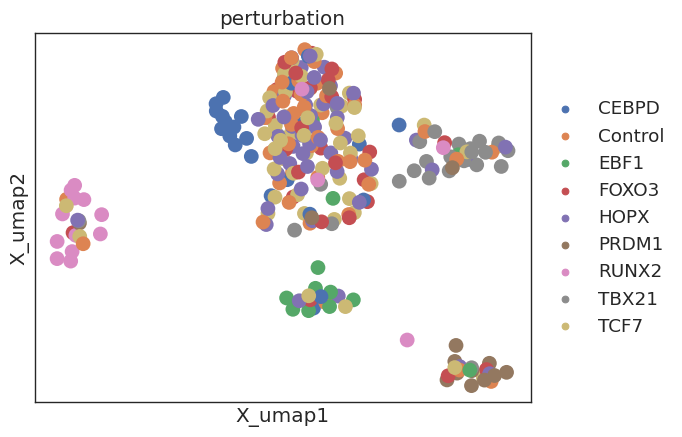

In [49]:
sc.pl.embedding(SEACell_mdata, color='perturbation', basis='X_umap')

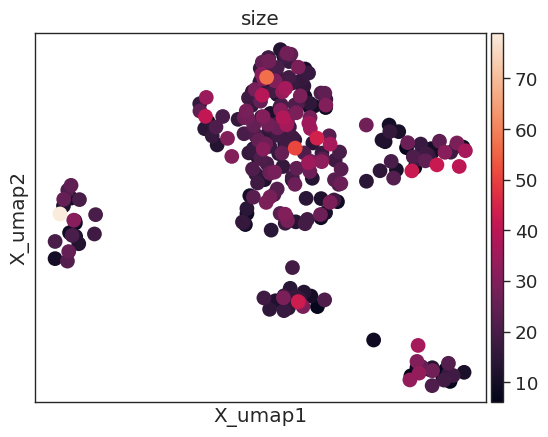

In [50]:
sc.pl.embedding(SEACell_mdata, color='size', basis='X_umap')

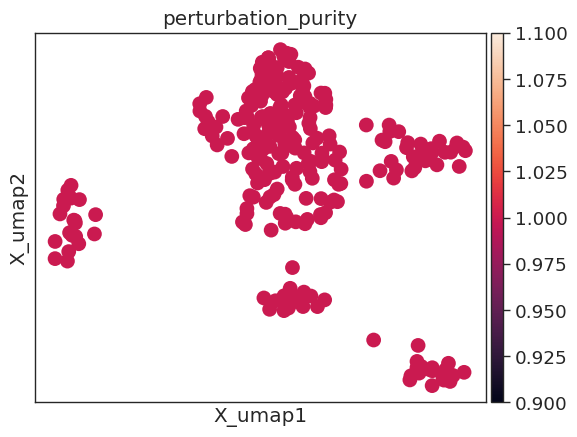

In [51]:
sc.pl.embedding(SEACell_mdata, color='perturbation_purity', basis='X_umap')

In [52]:
SEACell_mdata

MuData object with n_obs × n_vars = 266 × 118951
  obs:	'perturbation', 'perturbation_purity', 'compactness', 'size'
  uns:	'perturbation_colors'
  obsm:	'X_umap'
  2 modalities
    rna:	266 x 36601
      obs:	'perturbation', 'perturbation_purity'
      layers:	'raw'
    atac:	266 x 82350
      obs:	'perturbation', 'perturbation_purity'
      layers:	'raw'

In [53]:
pd.crosstab(SEACell_mdata.obs['perturbation'],(SEACell_mdata.obs['size'] >= 10), normalize=0)

size,False,True
perturbation,,
CEBPD,0.041667,0.958333
Control,0.023810,0.976190
EBF1,0.000000,1.000000
FOXO3,0.178571,0.821429
HOPX,0.040000,0.960000
PRDM1,0.142857,0.857143
RUNX2,0.125000,0.875000
TBX21,0.035714,0.964286
TCF7,0.120000,0.880000


In [54]:
## Looking at counts per metacell
sc.pp.calculate_qc_metrics(SEACell_mdata['rna'], inplace=True)

In [55]:
SEACell_mdata['rna'].obs['total_counts'].describe()

count       266.000000
mean      85865.980366
std       40375.873467
min       24950.736713
25%       57279.177979
50%       78954.196190
75%      108984.222221
max      335998.655379
Name: total_counts, dtype: float64

In [56]:
## The variability is very large - best to scale
## 10,000 for RNA
## 100,000 for ATAC

In [57]:
sc.pp.normalize_total(SEACell_mdata['rna'], target_sum=1e4)
sc.pp.normalize_total(SEACell_mdata['atac'], target_sum=1e5)

In [58]:
SEACell_mdata

MuData object with n_obs × n_vars = 266 × 118951
  obs:	'perturbation', 'perturbation_purity', 'compactness', 'size'
  uns:	'perturbation_colors'
  obsm:	'X_umap'
  2 modalities
    rna:	266 x 36601
      obs:	'perturbation', 'perturbation_purity', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
      var:	'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
      layers:	'raw'
    atac:	266 x 82350
      obs:	'perturbation', 'perturbation_purity'
      layers:	'raw'

In [59]:
## Exporting SEAcells object
SEACell_mdata.write((work_dir + "seacells_annot.h5mu"))

In [60]:
## Also export SEAcells with at least 10 cells 
SEACell_mdata[SEACell_mdata.obs['size'] >= 10].write((work_dir + "seacells_annot_min10cells.h5mu"))